# LeetCode #1184: Distance Between Bus Stops

https://leetcode.com/problems/distance-between-bus-stops/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n)$ | $O(1)$ |
| **Optimal: Two-Direction Min ★** | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Walk from `source` to `destination` in one direction summing distances, then in the reverse direction. Both passes are $O(n)$, making the overall approach correct but traversing the array twice unnecessarily.

### Optimal: Two-Direction Min ★
Compute the total length of the route in one pass. Then sum only the clockwise segment from `source` to `destination`. The counter-clockwise distance is `total - clockwise`. Return the minimum of the two in a single scan of the array.

**Constraints:**
* $1 \leq n \leq 10^4$
* $distance[i] \geq 0$
* $0 \leq start, destination < n$


## Solutions

### C#


In [ ]:
public int DistanceBetweenBusStops(int[] distance, int start, int destination) {
    // Ensure start < destination for consistent clockwise accumulation
    if (start > destination) { int t = start; start = destination; destination = t; }
    int clockwise = 0, total = 0;
    for (int i = 0; i < distance.Length; i++) {
        total += distance[i];
        // Accumulate only the segment between the two stops
        if (i >= start && i < destination) clockwise += distance[i];
    }
    // The shorter direction is the answer
    return Math.Min(clockwise, total - clockwise);
}


### Python


In [ ]:
def distance_between_bus_stops(distance: list[int], start: int, destination: int) -> int:
    if start > destination:
        start, destination = destination, start
    # Clockwise arc from start to destination
    clockwise = sum(distance[start:destination])
    total = sum(distance)
    # Return the shorter of the two circular arcs
    return min(clockwise, total - clockwise)


### Go


In [ ]:
func distanceBetweenBusStops(distance []int, start int, destination int) int {
    if start > destination {
        start, destination = destination, start
    }
    clockwise, total := 0, 0
    for i, d := range distance {
        total += d
        // Sum only the arc between the two stop indices
        if i >= start && i < destination {
            clockwise += d
        }
    }
    if clockwise < total-clockwise {
        return clockwise
    }
    return total - clockwise
}


### Rust


In [ ]:
pub fn distance_between_bus_stops(distance: Vec<i32>, start: i32, destination: i32) -> i32 {
    let (s, d) = if start <= destination {
        (start as usize, destination as usize)
    } else {
        (destination as usize, start as usize)
    };
    // Arc from s to d (clockwise) and the complement (counter-clockwise)
    let clockwise: i32 = distance[s..d].iter().sum();
    let total: i32 = distance.iter().sum();
    clockwise.min(total - clockwise)
}


## Example Scenarios

### 1. Common Case — The Long Way Round Is Shorter
**Input:** `distance = [1,2,3,4]`, `start = 0`, `destination = 3`

`distance[i]` is the hop from stop $i$ to stop $i+1$, with the last entry wrapping back to stop 0. The forward arc $0 \to 1 \to 2 \to 3$ costs $1 + 2 + 3 = 6$; the total loop is 10, so the backward arc $0 \to 3$ costs $10 - 6 = 4$. Answer **4** — three hops beaten by one.

### 2. Slightly Complex — Arguments in the Wrong Order
**Input:** `distance = [7,10,1,12]`, `start = 3`, `destination = 0`

The slice `distance[start:destination]` would be empty with $start > destination$, so the code swaps them first. After the swap the forward arc is $7 + 10 + 1 = 18$ and the backward arc is $30 - 18 = 12$. Answer **12**. The swap is sound because the ring is undirected: the distance from $a$ to $b$ equals the distance from $b$ to $a$.

### 3. Edge Case: Time Factor — Almost All the Way Around
**Input:** `distance = [1,1,1,1,1,1,1,1,1,1,1,1]`, `start = 0`, `destination = 11`

The forward arc covers 11 of the 12 hops and costs 11; the backward arc is the single wrap-around hop, costing 1. Answer **1**. Both `sum(distance)` and `sum(distance[start:destination])` are full linear scans, so the cost is $O(n)$ whatever the answer turns out to be — at $n = 10^4$ that is two passes of at most $10^4$ additions each, with no early exit.

### 4. Edge Case: Space Factor — A Perfect Tie
**Input:** `distance = [5,5,5,5,5,5,5,5,5,5]`, `start = 2`, `destination = 7`

Both arcs cover five equal hops, so each costs 25 and `min` is indifferent. Answer **25**. The memory story: nothing is allocated at all — `clockwise` and `total` are two integers and the ring is walked by slicing the input, so the auxiliary space is $O(1)$ no matter how many stops there are. (Python's slice does copy, so a strictly $O(1)$ version would accumulate in a loop instead.)

### 5. Almost-Impossible but Plausible — A Zero-Length Arc
**Input:** `distance = [0,0,0,100]`, `start = 0`, `destination = 3`

The constraints allow $distance[i] = 0$, so the forward arc $0 + 0 + 0$ is free while the single backward hop costs 100. Answer **0**, even though the stops are three hops apart. The same degenerate shape appears when $start = destination$: the slice is empty, the forward arc is 0, and `min(0, total)` correctly returns 0.

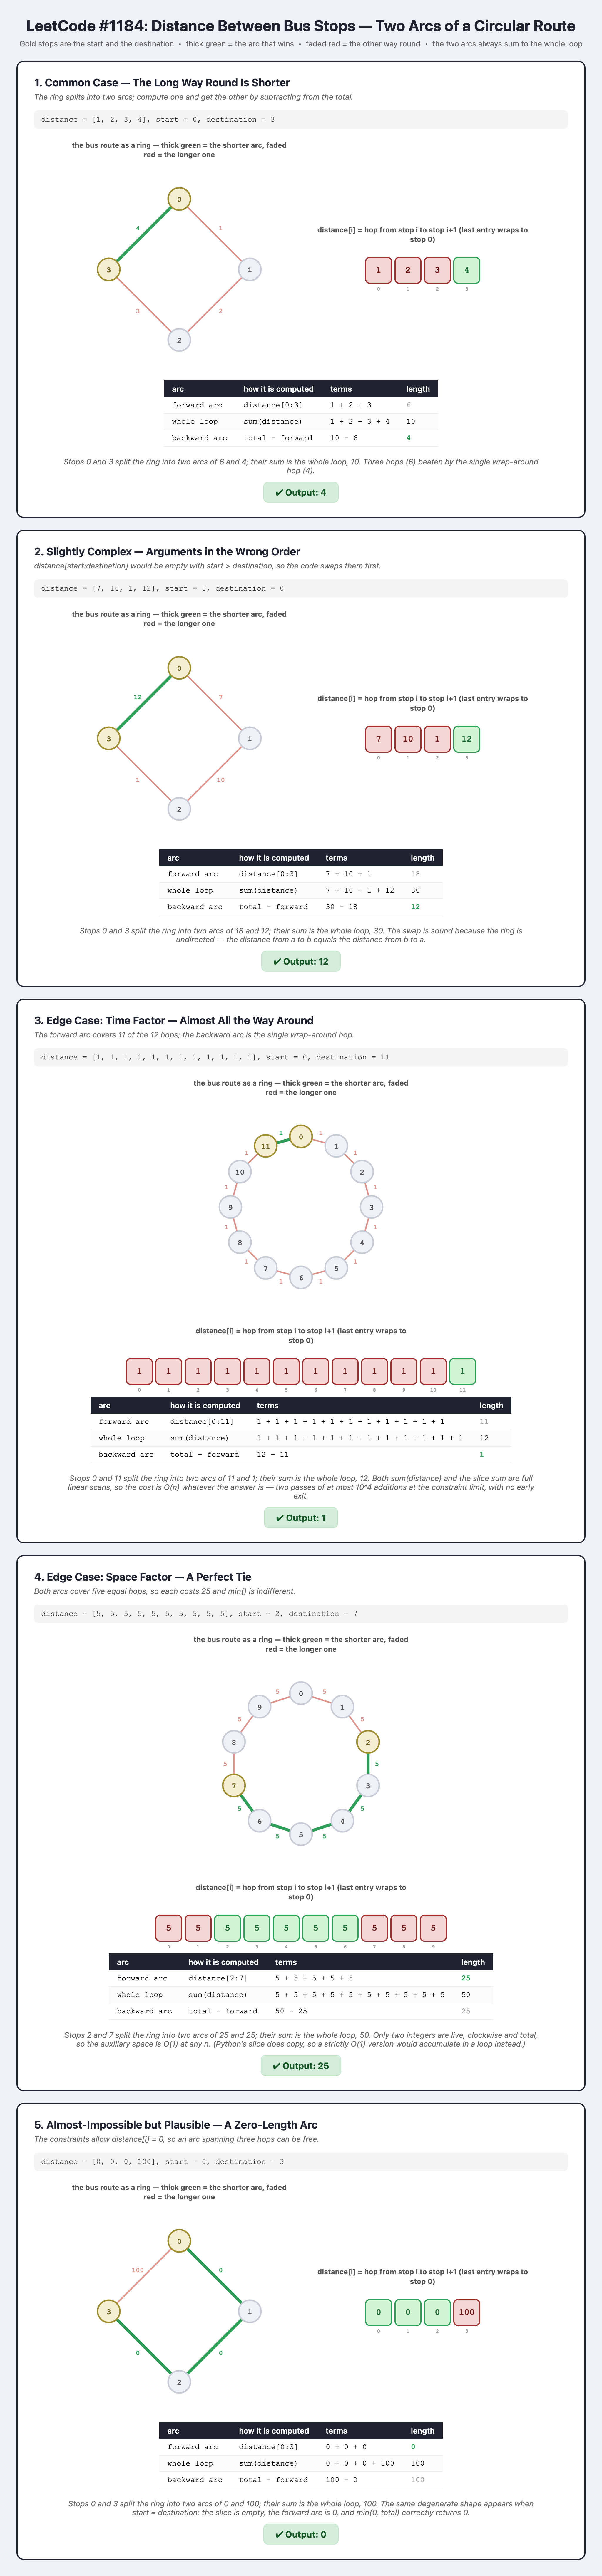